# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Student Dropout Dataset](https://www.kaggle.com/datasets/vedauv/student-dropout-and-academic-success-12k/data?select=student_dropout.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.	

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

/kaggle/input/datasets/vedauv/student-dropout-and-academic-success-12k/README.md
/kaggle/input/datasets/vedauv/student-dropout-and-academic-success-12k/datasheet.md
/kaggle/input/datasets/vedauv/student-dropout-and-academic-success-12k/student_dropout.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('student_dropout.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,student_id,age_at_enrollment,gender,international,first_generation,scholarship,program,high_school_gpa,admission_score,attendance_pct,study_hours_week,part_time_job_hours,lms_logins_week,ai_tool_hours_week,stress_index,commute_km,financial_aid_usd_k,tuition_debt,sem1_gpa,sem1_credits_passed_pct,sem2_gpa,final_gpa,dropout
0,S00001,18,Male,0,0,1,Law,1.84,60,75.9,1.4,1,2.4,3.0,6.1,8.8,5.0,0,1.41,68.8,1.19,1.32,1
1,S00002,18,Male,1,0,0,Natural Sciences,4.00,89,90.2,13.2,0,7.4,0.5,5.0,12.7,3.6,0,3.49,87.3,3.35,3.59,0
2,S00003,18,Male,0,0,0,Computer Science,3.21,65,81.9,4.7,12,5.5,1.0,6.8,10.5,5.3,0,2.67,73.3,2.48,2.84,0
3,S00004,18,Female,0,1,0,Engineering,2.10,57,83.6,5.8,36,3.0,2.7,5.2,31.7,0.0,0,3.02,84.0,3.31,3.15,0
4,S00005,19,Female,0,0,0,Natural Sciences,3.31,55,83.4,5.4,0,2.7,1.0,6.7,6.1,2.2,0,2.01,73.2,1.96,2.28,0


## last Five row

In [4]:
df.tail()

,student_id,age_at_enrollment,gender,international,first_generation,scholarship,program,high_school_gpa,admission_score,attendance_pct,study_hours_week,part_time_job_hours,lms_logins_week,ai_tool_hours_week,stress_index,commute_km,financial_aid_usd_k,tuition_debt,sem1_gpa,sem1_credits_passed_pct,sem2_gpa,final_gpa,dropout
11995,S11996,19,Male,0,0,0,Engineering,3.77,85,71.1,9.3,8,2.9,3.0,4.3,17.4,9.9,0,2.88,88.3,2.78,2.49,0
11996,S11997,19,Male,0,0,1,Engineering,3.14,60,68.6,4.3,6,2.6,4.9,7.3,52.0,6.2,0,1.67,75.2,1.20,1.40,1
11997,S11998,19,Non-binary,0,0,0,Computer Science,2.92,65,95.5,17.2,1,5.9,3.6,2.0,58.6,9.3,0,4.00,100.0,4.00,3.78,0
11998,S11999,20,Female,0,0,0,Law,3.22,78,87.2,15.5,13,5.5,2.7,5.5,7.2,5.6,0,2.81,89.0,2.69,2.83,0
11999,S12000,21,Female,0,1,0,Computer Science,3.23,76,100.0,24.9,12,40.0,3.5,7.0,5.0,2.2,0,3.99,94.1,4.00,4.00,0


## Shape of our dataset

In [5]:
df.shape

(12000, 23)

## List out all columns

In [6]:
df.columns

Index(['student_id', 'age_at_enrollment', 'gender', 'international',
       'first_generation', 'scholarship', 'program', 'high_school_gpa',
       'admission_score', 'attendance_pct', 'study_hours_week',
       'part_time_job_hours', 'lms_logins_week', 'ai_tool_hours_week',
       'stress_index', 'commute_km', 'financial_aid_usd_k', 'tuition_debt',
       'sem1_gpa', 'sem1_credits_passed_pct', 'sem2_gpa', 'final_gpa',
       'dropout'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

student_id                  object
age_at_enrollment            int64
gender                      object
international                int64
first_generation             int64
scholarship                  int64
program                     object
high_school_gpa            float64
admission_score              int64
attendance_pct             float64
study_hours_week           float64
part_time_job_hours          int64
lms_logins_week            float64
ai_tool_hours_week         float64
stress_index               float64
commute_km                 float64
financial_aid_usd_k        float64
tuition_debt                 int64
sem1_gpa                   float64
sem1_credits_passed_pct    float64
sem2_gpa                   float64
final_gpa                  float64
dropout                      int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               12000 non-null  object 
 1   age_at_enrollment        12000 non-null  int64  
 2   gender                   12000 non-null  object 
 3   international            12000 non-null  int64  
 4   first_generation         12000 non-null  int64  
 5   scholarship              12000 non-null  int64  
 6   program                  12000 non-null  object 
 7   high_school_gpa          12000 non-null  float64
 8   admission_score          12000 non-null  int64  
 9   attendance_pct           12000 non-null  float64
 10  study_hours_week         12000 non-null  float64
 11  part_time_job_hours      12000 non-null  int64  
 12  lms_logins_week          12000 non-null  float64
 13  ai_tool_hours_week       12000 non-null  float64
 14  stress_index          

## Check Null Value

In [9]:
df.isnull().sum()

student_id                 0
age_at_enrollment          0
gender                     0
international              0
first_generation           0
scholarship                0
program                    0
high_school_gpa            0
admission_score            0
attendance_pct             0
study_hours_week           0
part_time_job_hours        0
lms_logins_week            0
ai_tool_hours_week         0
stress_index               0
commute_km                 0
financial_aid_usd_k        0
tuition_debt               0
sem1_gpa                   0
sem1_credits_passed_pct    0
sem2_gpa                   0
final_gpa                  0
dropout                    0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,age_at_enrollment,international,first_generation,scholarship,high_school_gpa,admission_score,attendance_pct,study_hours_week,part_time_job_hours,lms_logins_week,ai_tool_hours_week,stress_index,commute_km,financial_aid_usd_k,tuition_debt,sem1_gpa,sem1_credits_passed_pct,sem2_gpa,final_gpa,dropout
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,20.134167,0.120167,0.302333,0.252250,2.999956,70.081083,80.262908,10.823108,8.928583,5.377067,2.040950,5.367250,14.538992,4.670783,0.144583,2.680763,79.594817,2.673756,2.584118,0.220000
std,2.219552,0.325170,0.459288,0.434322,0.490542,11.624590,9.149946,5.351061,8.648095,3.499291,1.887971,1.850638,15.182413,3.091491,0.351695,0.679750,12.007251,0.752003,0.861725,0.414264
min,18.000000,0.000000,0.000000,0.000000,1.500000,30.000000,45.500000,1.000000,0.000000,0.500000,0.100000,1.000000,0.500000,0.000000,0.000000,0.000000,30.600000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,2.670000,62.000000,74.000000,7.000000,3.000000,3.000000,0.900000,4.100000,5.300000,2.300000,0.000000,2.220000,71.300000,2.150000,2.010000,0.000000
50%,19.000000,0.000000,0.000000,0.000000,3.000000,70.000000,80.300000,10.700000,6.000000,4.500000,1.500000,5.400000,9.800000,4.500000,0.000000,2.680000,79.900000,2.690000,2.660000,0.000000
75%,21.000000,0.000000,1.000000,1.000000,3.340000,78.000000,86.500000,14.500000,12.000000,6.800000,2.525000,6.600000,17.900000,6.700000,0.000000,3.170000,88.500000,3.220000,3.230000,0.000000
max,38.000000,1.000000,1.000000,1.000000,4.000000,100.000000,100.000000,31.700000,40.000000,40.000000,15.000000,10.000000,120.000000,18.500000,1.000000,4.000000,100.000000,4.000000,4.000000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

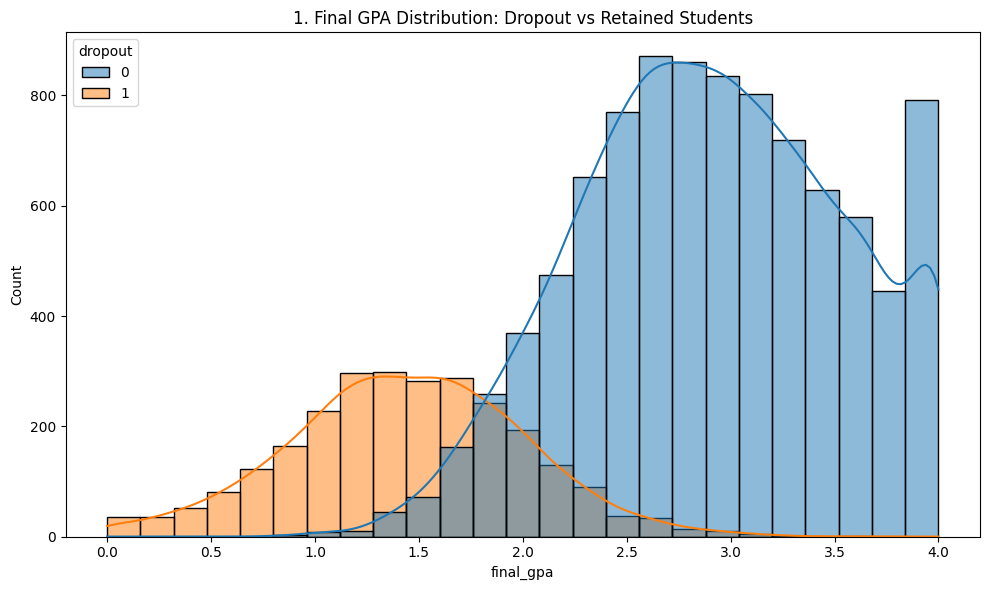

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='final_gpa', hue='dropout', kde=True, bins=25, multiple='layer')
plt.title(f'{plot_no}. Final GPA Distribution: Dropout vs Retained Students')
show_fig()
plot_no += 1

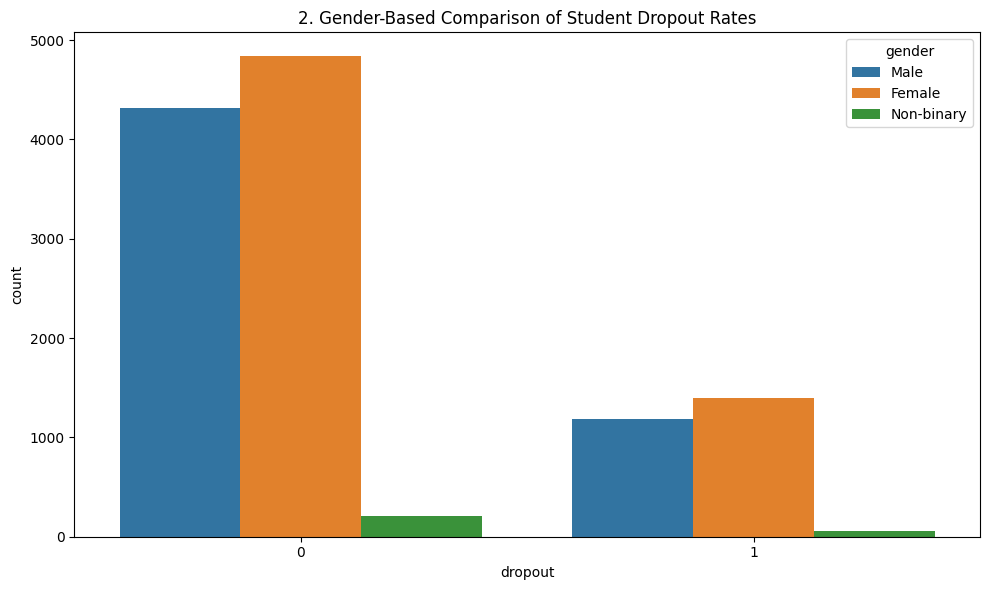

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='dropout', hue='gender')
plt.title(f'{plot_no}. Gender-Based Comparison of Student Dropout Rates')
show_fig()
plot_no += 1

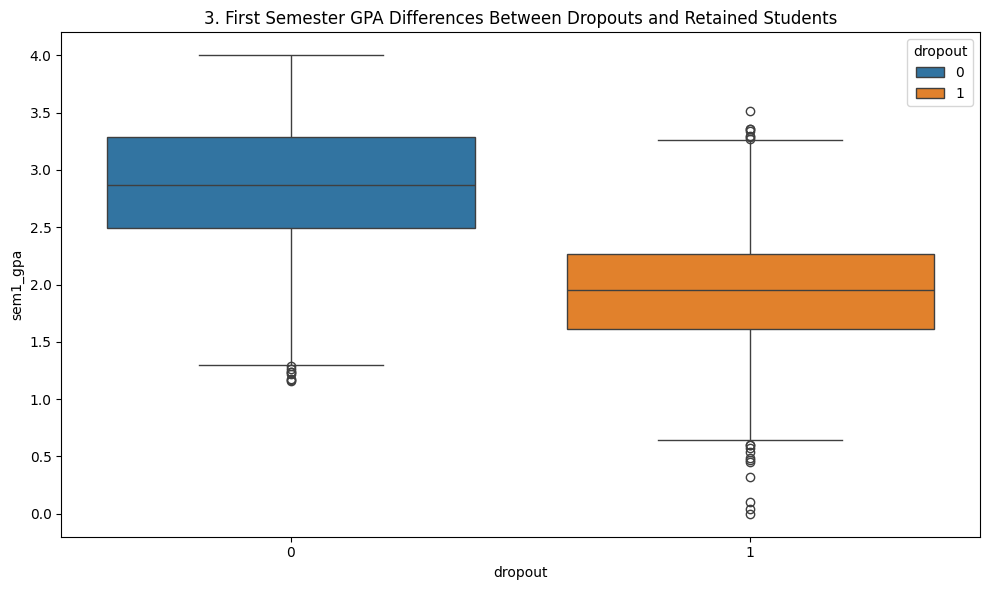

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='dropout', y='sem1_gpa', hue='dropout')
plt.title(f'{plot_no}. First Semester GPA Differences Between Dropouts and Retained Students')
show_fig()
plot_no += 1

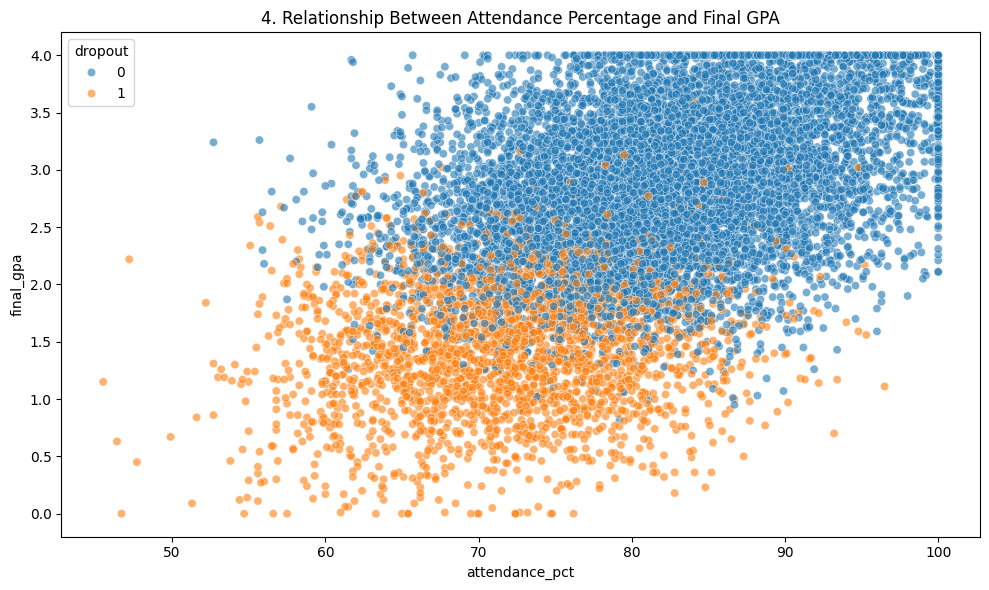

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='attendance_pct', y='final_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Attendance Percentage and Final GPA')
show_fig()
plot_no += 1

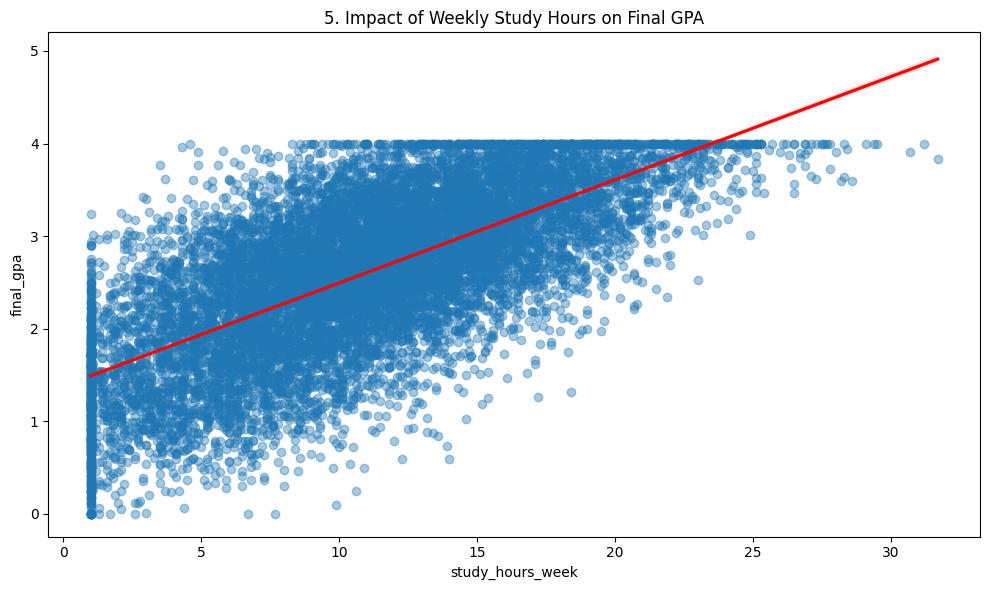

In [17]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='study_hours_week', y='final_gpa', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Impact of Weekly Study Hours on Final GPA')
show_fig()
plot_no += 1

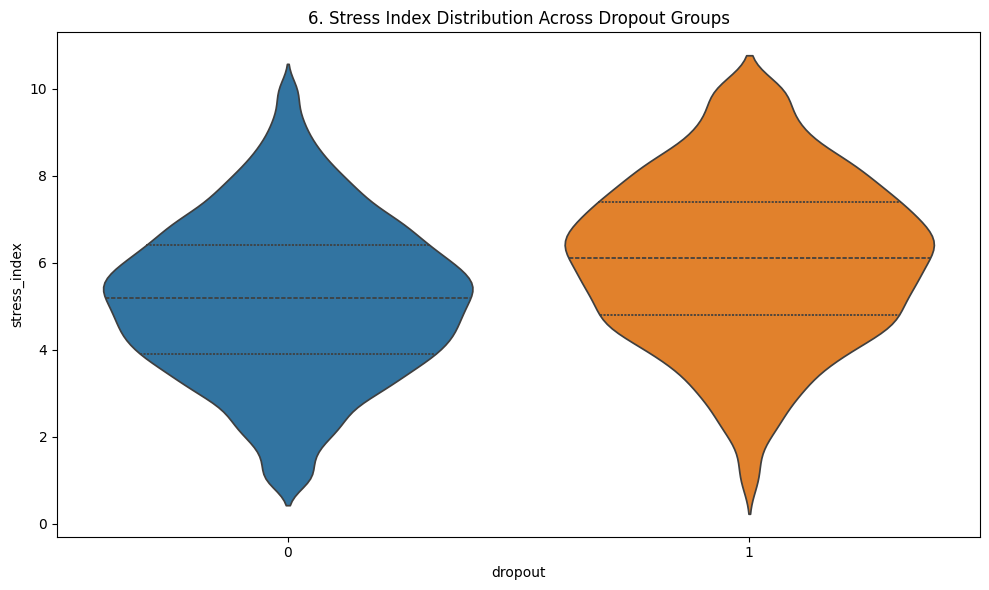

In [18]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='dropout', y='stress_index', hue='dropout', inner='quartile', legend=False)
plt.title(f'{plot_no}. Stress Index Distribution Across Dropout Groups')
show_fig()
plot_no += 1

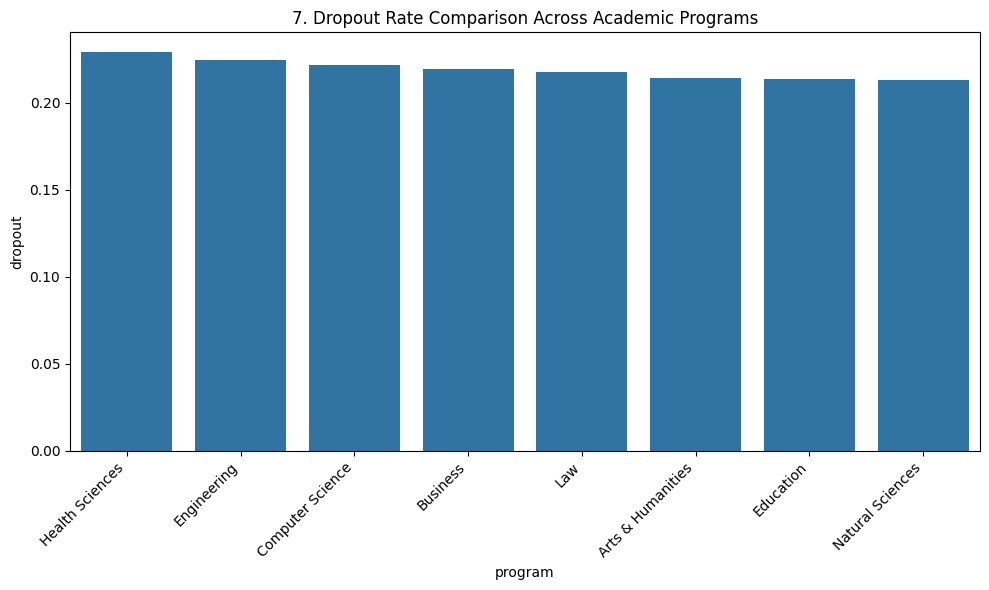

In [19]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='program', y='dropout', errorbar=None, order=df.groupby('program')['dropout'].mean().sort_values(ascending=False).index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Dropout Rate Comparison Across Academic Programs')
show_fig()
plot_no += 1

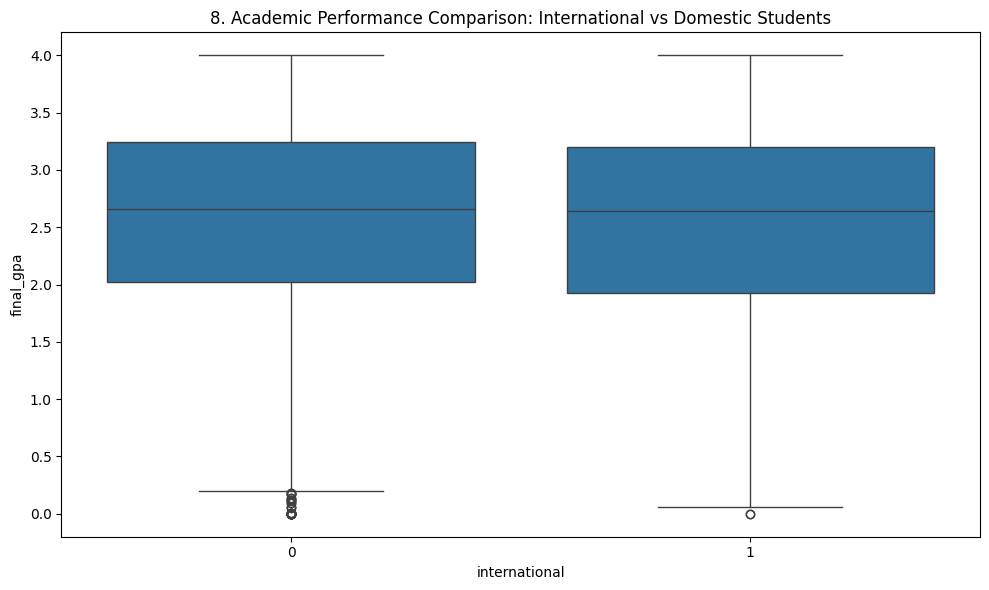

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='international', y='final_gpa')
plt.title(f'{plot_no}. Academic Performance Comparison: International vs Domestic Students')
show_fig()
plot_no += 1

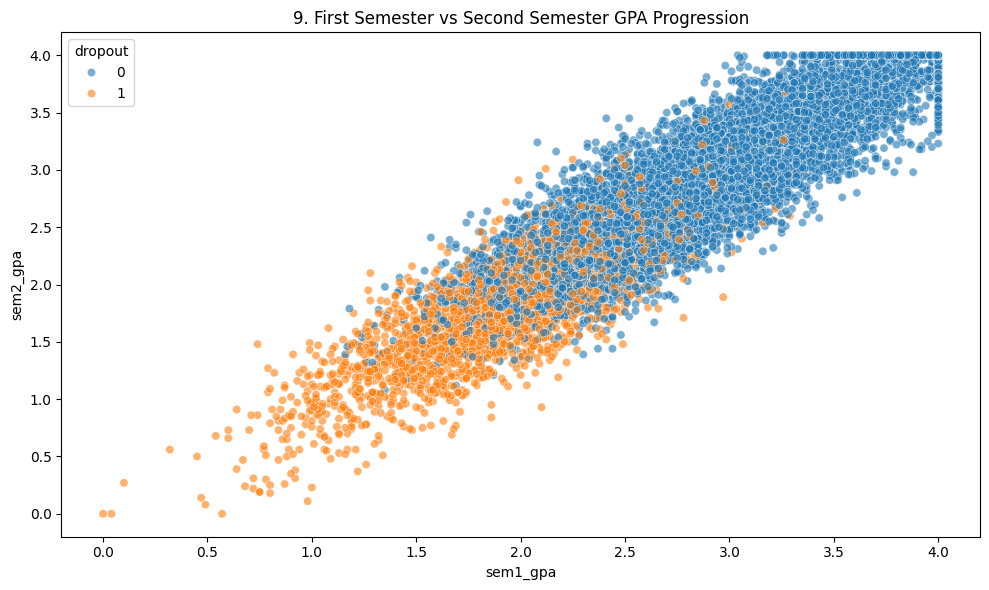

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='sem1_gpa', y='sem2_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. First Semester vs Second Semester GPA Progression')
show_fig()
plot_no += 1

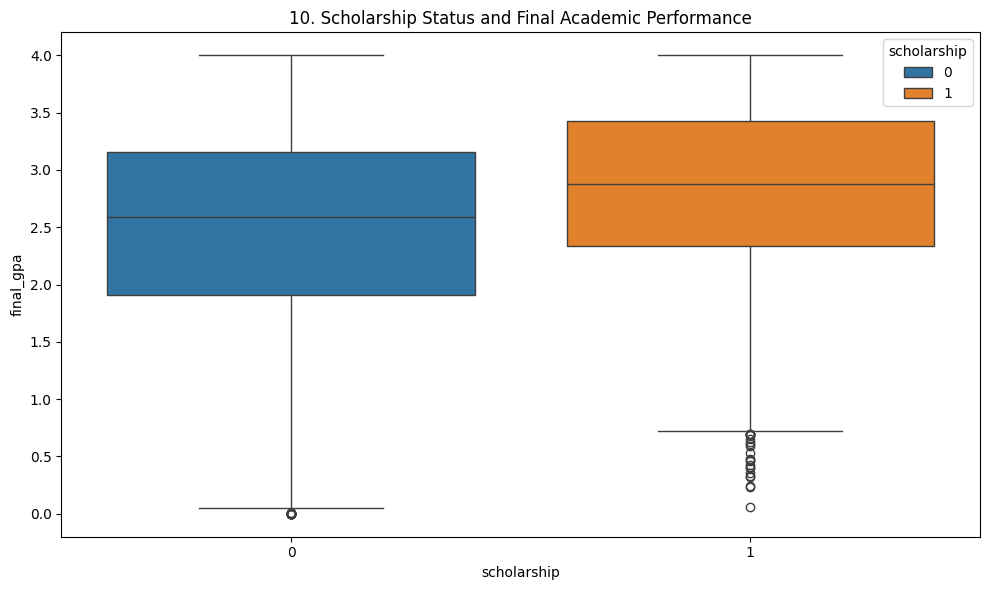

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='scholarship', y='final_gpa', hue='scholarship')
plt.title(f'{plot_no}. Scholarship Status and Final Academic Performance')
show_fig()
plot_no += 1

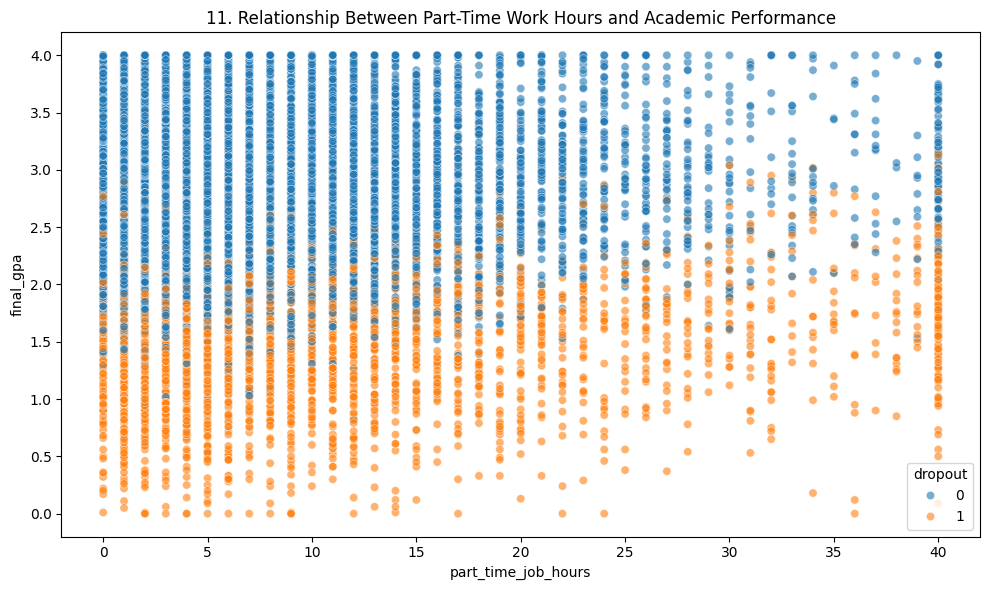

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='part_time_job_hours', y='final_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Part-Time Work Hours and Academic Performance')
show_fig()
plot_no += 1

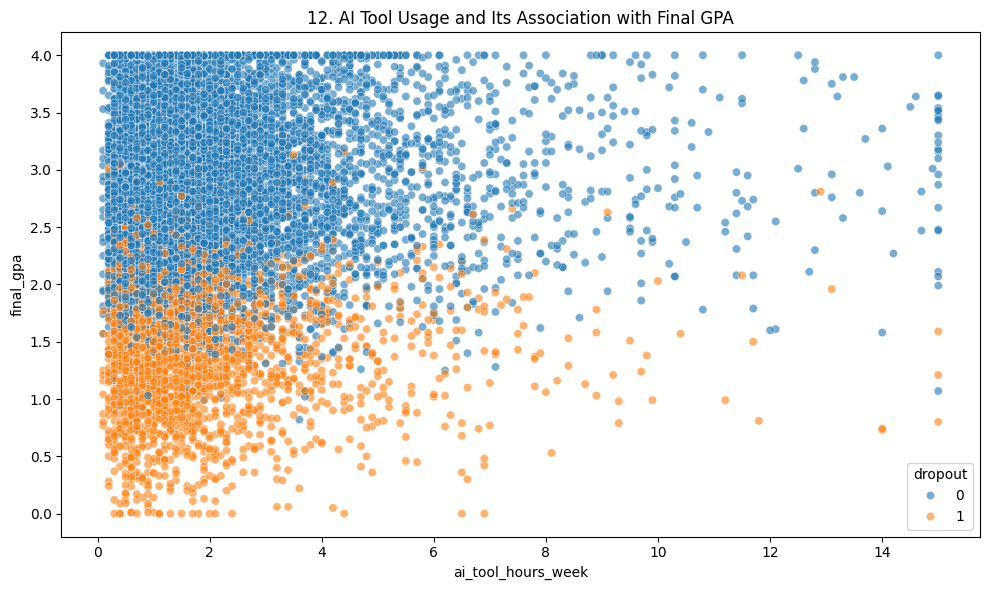

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='ai_tool_hours_week', y='final_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. AI Tool Usage and Its Association with Final GPA')
show_fig()
plot_no += 1

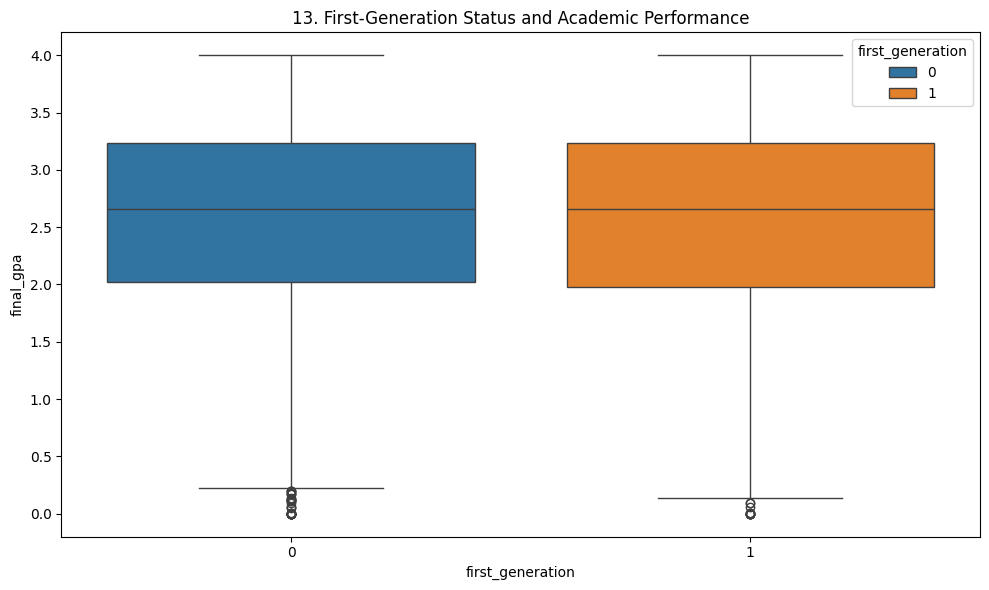

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='first_generation', y='final_gpa', hue='first_generation')
plt.title(f'{plot_no}. First-Generation Status and Academic Performance')
show_fig()
plot_no += 1

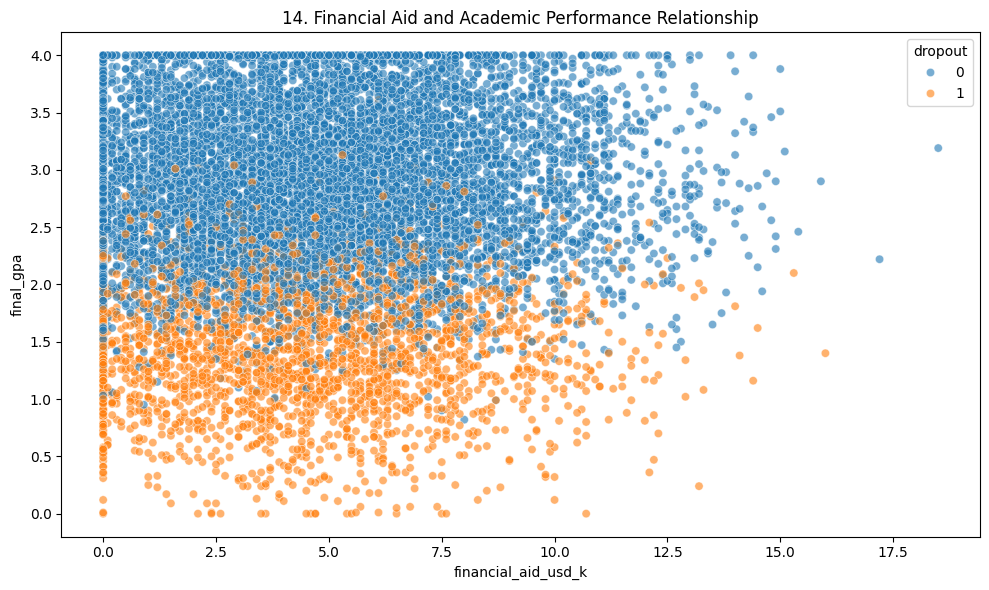

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='financial_aid_usd_k', y='final_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. Financial Aid and Academic Performance Relationship')
show_fig()
plot_no += 1

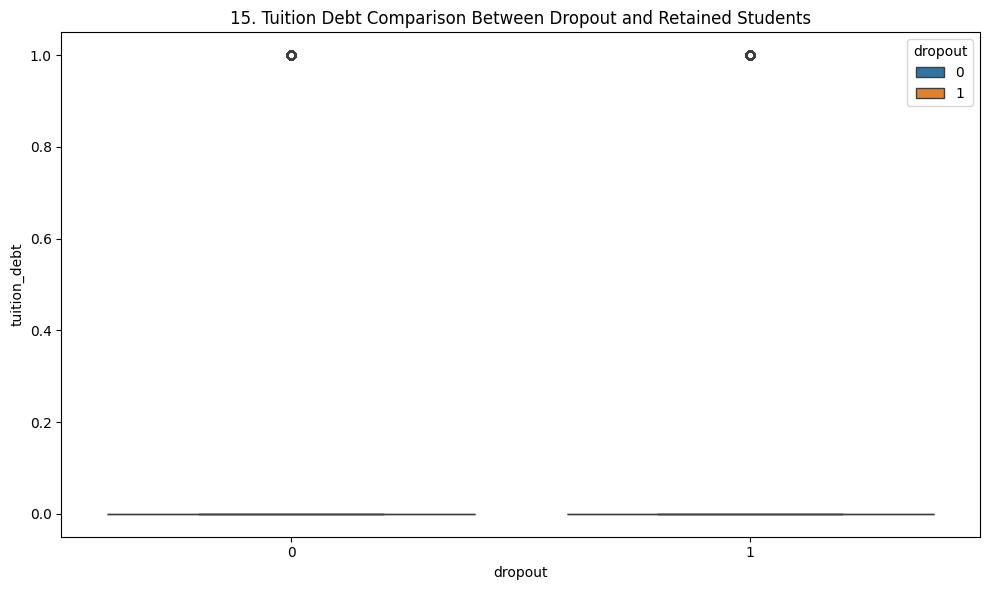

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='dropout', y='tuition_debt', hue='dropout')
plt.title(f'{plot_no}. Tuition Debt Comparison Between Dropout and Retained Students')
show_fig()
plot_no += 1

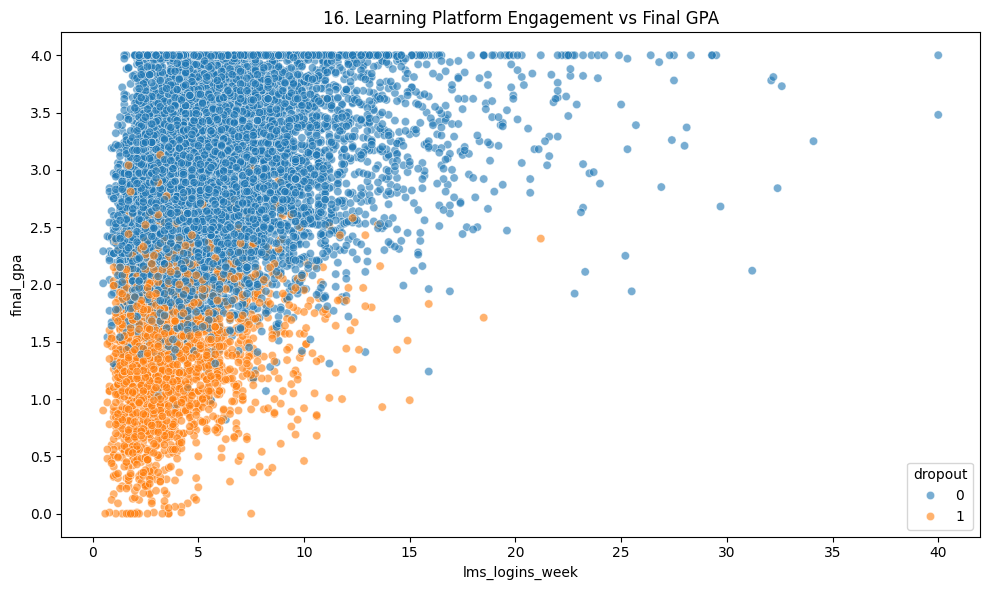

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='lms_logins_week', y='final_gpa', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. Learning Platform Engagement vs Final GPA')
show_fig()
plot_no += 1

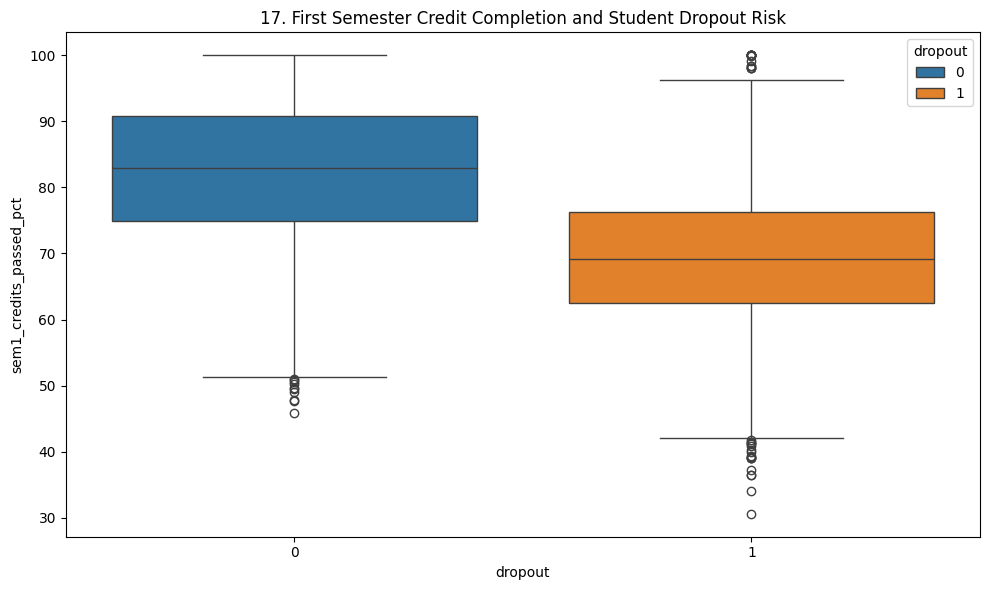

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='dropout', y='sem1_credits_passed_pct', hue='dropout')
plt.title(f'{plot_no}. First Semester Credit Completion and Student Dropout Risk')
show_fig()
plot_no += 1

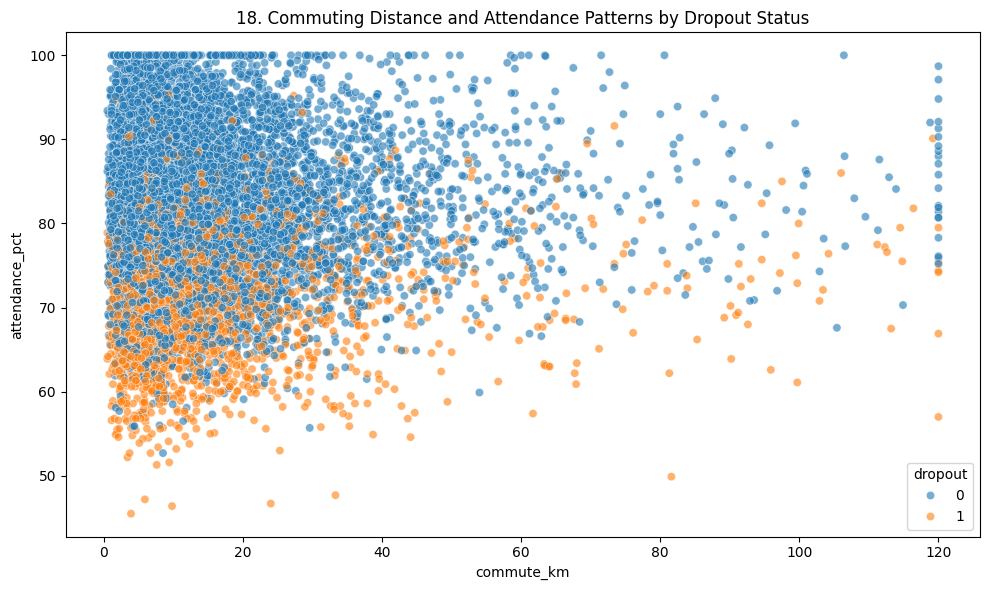

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='commute_km', y='attendance_pct', hue='dropout', alpha=0.6)
plt.title(f'{plot_no}. Commuting Distance and Attendance Patterns by Dropout Status')
show_fig()
plot_no += 1

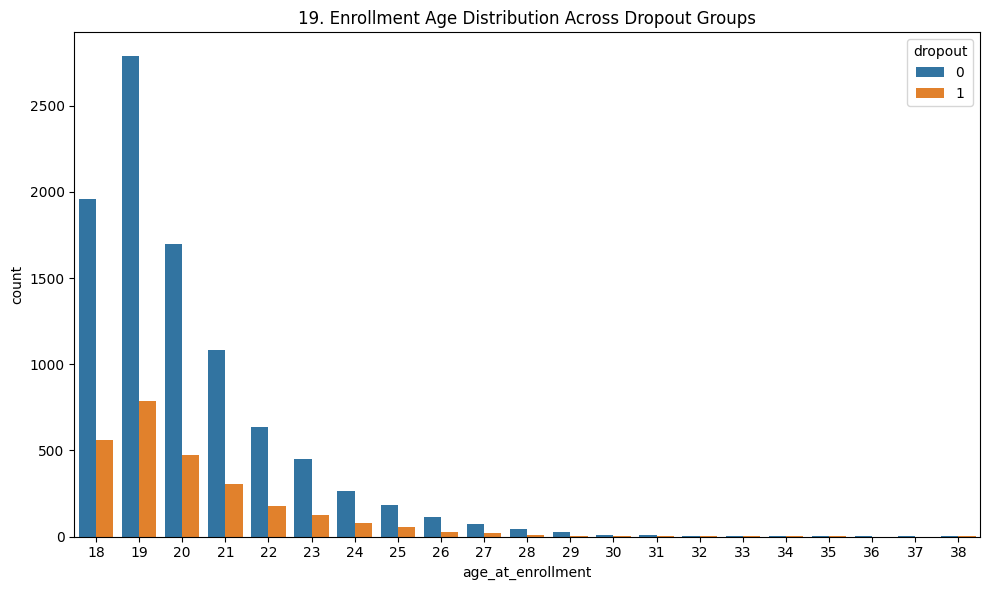

In [31]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='age_at_enrollment', hue='dropout')
plt.title(f'{plot_no}. Enrollment Age Distribution Across Dropout Groups')
show_fig()
plot_no += 1

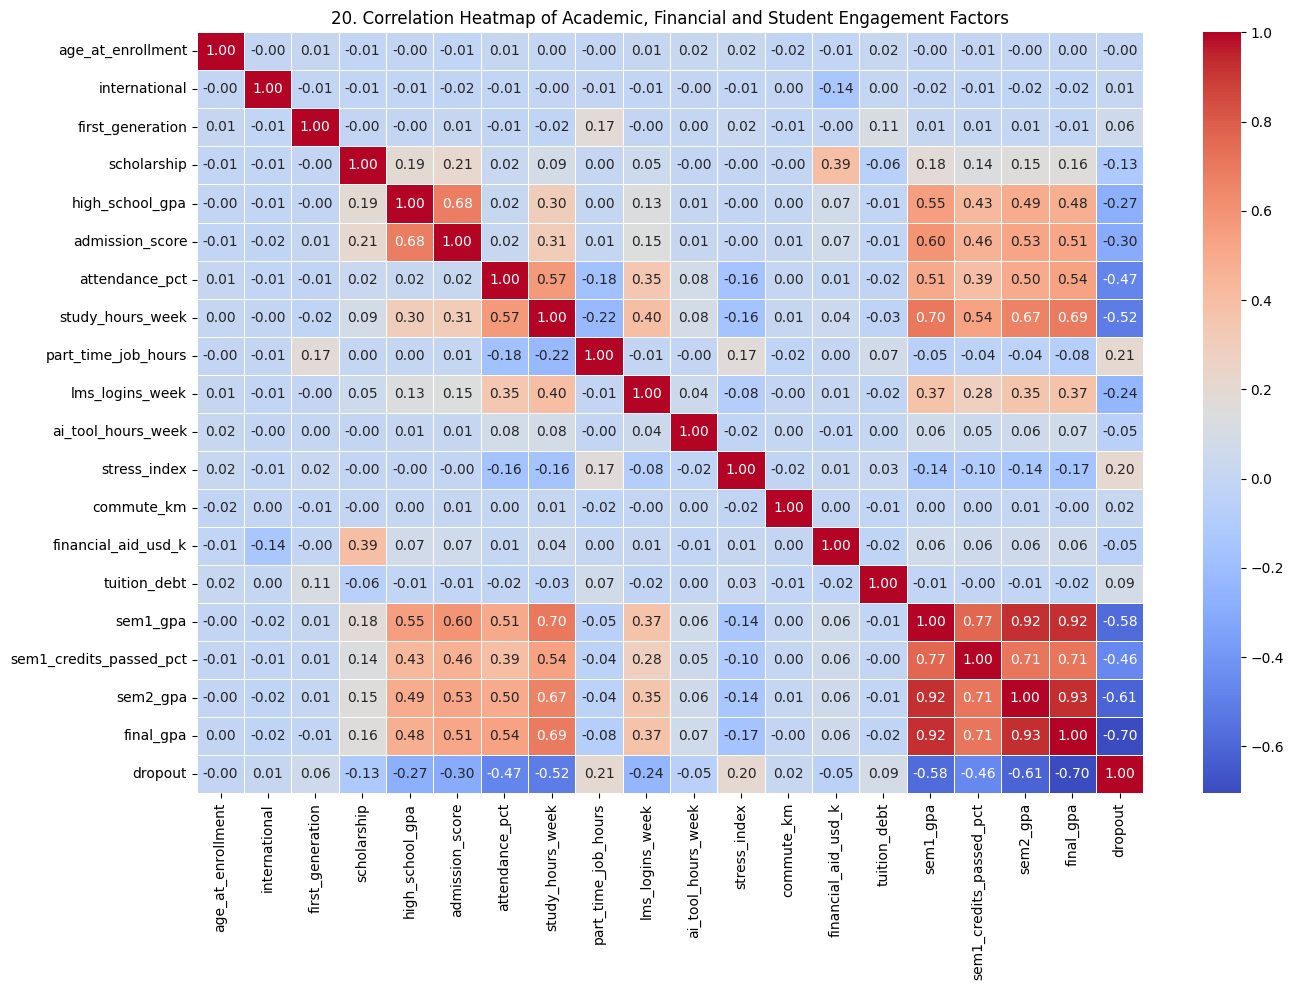

In [32]:
fig = plt.figure(figsize=(14,10))
corr = df.drop(columns=['student_id'], errors='ignore').select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Academic, Financial and Student Engagement Factors')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [33]:
X = df.drop(columns=['dropout', 'student_id'], errors='ignore')
y = df['dropout']

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess numerical and categorical features

In [35]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Split dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Build Gradient Boosting model

In [37]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

## Train model

In [38]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age_at_enrollment', 'international', 'first_generation', 'scholarship',
       'high_school_gpa', 'admission_score', 'attendance_pct',
       'study_hours_week', 'part_time_job_hours', 'lms_logins_week',...
       'sem1_credits_passed_pct', 'sem2_gpa', 'final_gpa'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'program'], dtype='object'))])),
                ('classifier',
                 HistGradientBoostingClassifier(l2_regularization=1.0,
                                                learning_rate=0.08,
                                                max_iter=300, max_leaf_nodes=20,
                                                random_state=42))])

## Predict test data

In [39]:
y_pred = model.predict(X_test)

## Evaluate model

In [40]:
print("Model: Hist Gradient Boosting Classifier")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model: Hist Gradient Boosting Classifier
Accuracy: 94.29 %

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1872
           1       0.89      0.84      0.87       528

    accuracy                           0.94      2400
   macro avg       0.92      0.91      0.92      2400
weighted avg       0.94      0.94      0.94      2400



## Plot confusion matrix

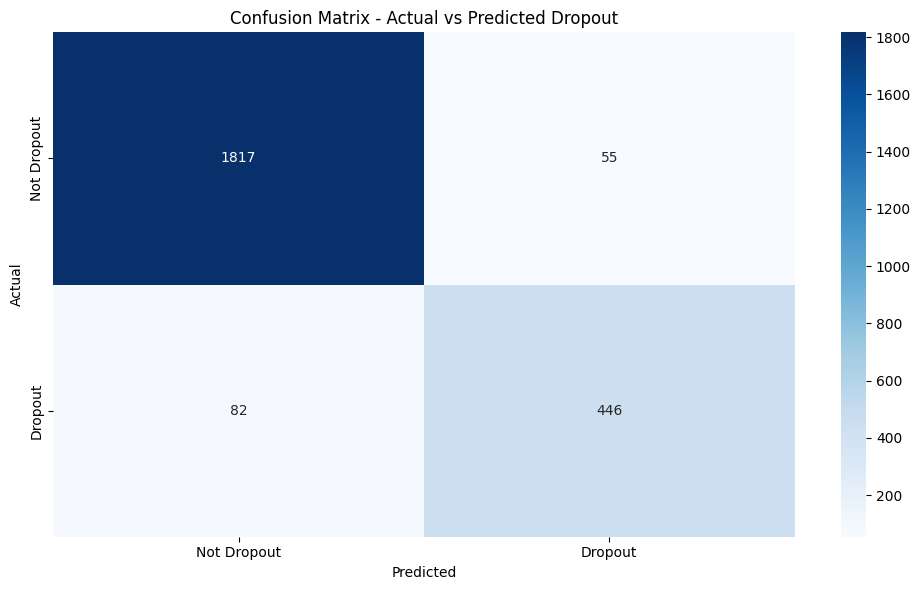

In [41]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Dropout', 'Dropout'],
            yticklabels=['Not Dropout', 'Dropout'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Actual vs Predicted Dropout')
show_fig()
plot_no += 1